In [2]:
import sys
sys.path.append("../")

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from qiskit.quantum_info import Statevector, SparsePauliOp
from qitp.engine.unitary_approximation import UnitaryApproximation
from qitp.engine.propagation import QITEPropagation
from qitp.engine.cqite_run import run_qite
from qitp.engine.prepare_state import constraint_rotation, prepare_state, density_from_rotations, support_only
from qitp.simulation.backend import SimulatorBackend

In [4]:
from qitp.ansatz.pauli_basis import (
    PauliBasis
)
from qitp.ansatz.commutator_basis import (
    CommutatorBasis
)

In [5]:
depth=1
dt=1e-1
nqubits = 3

In [6]:
nsteps=50
target=0.3

energies=[]
fidelities=[]
errors=[]
magnetizations=[]

In [7]:
from qiskit.quantum_info import SparsePauliOp

h = 0.25
J = 0.25

H = SparsePauliOp(
    [
        "XII",
        "IXI",
        "IIX",
        "ZZI",
        "ZIZ",
        "IZZ",
    ],
    coeffs=[h, h, h, J, J, J]
)

In [8]:
Mz = constraints = [
    SparsePauliOp(["YII"], coeffs=[1.0]),
    SparsePauliOp(["IYI"], coeffs=[1.0]),
    SparsePauliOp(["IIY"], coeffs=[1.0]),
]

Identity = SparsePauliOp(["III"],coeffs=[1.0])

In [9]:
H_eff = H + sum(Mz[1:], start=Mz[0])# + Identity

In [10]:
rotations = []

for constraint in Mz:

    rotations.append(
        constraint_rotation(
            constraint,
            target
        )
    )

In [11]:
rho = density_from_rotations(3, rotations, degree=2)

seeds = support_only(rho)

In [12]:
basis = CommutatorBasis.from_seed(hamiltonian=H_eff, seeds=seeds, depth=depth)

In [13]:
len(basis.paulis)

36

In [14]:
circuit = prepare_state(
    3,
    rotations
)

In [15]:
circuit = circuit.decompose()

In [16]:
approx = UnitaryApproximation(basis, trot=4)

backend = SimulatorBackend()

prop = QITEPropagation(
    H,
    backend,
    approx
)

prop.constraints = [
    Identity]
prop.constraints.extend(Mz)

In [32]:
from qiskit.quantum_info import Statevector

psi = Statevector.from_instruction(circuit)

In [34]:
results = run_qite(
    prop,
    circuit,
    H,
    Mz,
    dt,
    nsteps,
    state=None #Remove for exponential advantage
)

energies = results["energies"]
magnetizations = results["magnetizations"] #[np.sum(m) for m in results["magnetizations"]]
circuit = results["circuit"]

In [35]:
print(np.round(energies[-1],3))

-0.835


In [36]:
print(np.round(magnetizations[-1],3))

[0.273 0.273 0.268]


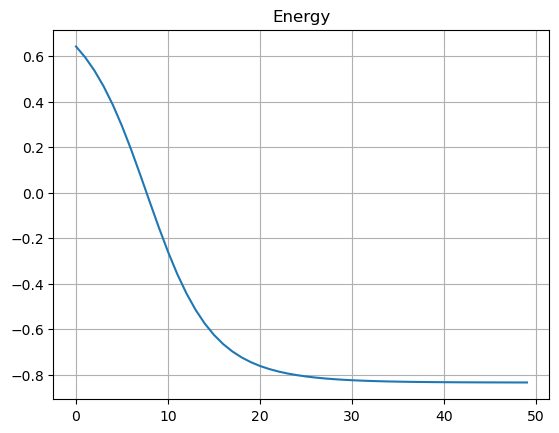

In [37]:
plt.plot(energies); plt.title('Energy'); plt.grid(); plt.show()

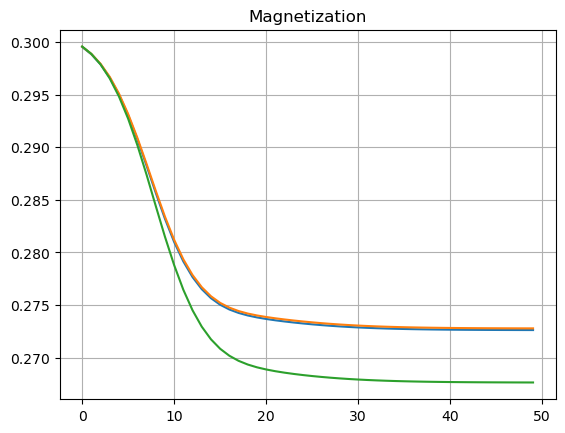

In [38]:
plt.plot(magnetizations); plt.title("Magnetization"); plt.grid(); plt.show()

In [44]:
import numpy as np
from scipy.optimize import root

Hm = H.to_matrix()

C = [
    SparsePauliOp(["YII"], coeffs=[1.0]).to_matrix(),
    SparsePauliOp(["IYI"], coeffs=[1.0]).to_matrix(),
    SparsePauliOp(["IIY"], coeffs=[1.0]).to_matrix(),
]


def constraints_of_lambda(lmbda):

    H_eff2 = Hm.copy()

    for a, Ck in zip(lmbda, C):
        H_eff2 += a * Ck

    eigvals, eigvecs = np.linalg.eigh(H_eff2)

    psi = eigvecs[:, 0]

    return np.array([
        np.real(
            np.vdot(
                psi,
                Ck @ psi
            )
        ) - target
        for Ck in C
    ])

sol = root(
    constraints_of_lambda,
    x0=np.zeros(3)
)

print("lambdas =", sol.x)

H_eff2 = Hm.copy()

for a, Ck in zip(sol.x, C):
    H_eff2 += a * Ck

eigvals, eigvecs = np.linalg.eigh(H_eff2)

psi = eigvecs[:, 0]

energy = np.real(
    np.vdot(
        psi,
        Hm @ psi
    )
)

print("Constrained energy =", energy)

for i, Ck in enumerate(C):
    print(
        f"constraint {i}",
        np.real(
            np.vdot(
                psi,
                Ck @ psi
            )
        )
    )

lambdas = [-0.08665049 -0.08665049 -0.08665049]
Constrained energy = -0.8280222724949527
constraint 0 0.29999999999999993
constraint 1 0.30000000000000004
constraint 2 0.3


In [117]:
evals = np.linalg.eigvalsh(
    H.to_matrix()
)

print("Exact spectrum")

print(np.round(evals,2))

Exact spectrum
[-3.46 -2.   -2.   -0.   -0.    0.    3.46  4.  ]


In [118]:
G = H_eff

In [102]:
psi = Statevector(circuit).data

vectors = []

for i in range(basis.size):

    P = basis.operator(i).to_matrix()

    v = P @ psi

    #
    # remove radial component
    #
    v -= psi * np.vdot(psi, v)

    vectors.append(
        np.real(v)
    )

T = np.column_stack(vectors)

print(
    "ITE tangent rank =",
    np.linalg.matrix_rank(
        T,
        tol=1e-10
    )
)

ITE tangent rank = 8


In [104]:
len(basis.paulis)

41

In [106]:
import numpy as np

basis=cb

def pauli_to_symplectic(label):

    n = len(label)

    x = np.zeros(
        n,
        dtype=np.uint8
    )

    z = np.zeros(
        n,
        dtype=np.uint8
    )

    for i, p in enumerate(label):

        if p == "X":
            x[i] = 1

        elif p == "Z":
            z[i] = 1

        elif p == "Y":
            x[i] = 1
            z[i] = 1

    return x, z


def op_to_symplectic(op):

    #
    # attenzione:
    # qui assumiamo che ogni operatore
    # della base sia una singola stringa Pauli
    #
    label = op.paulis[0].to_label()

    x, z = pauli_to_symplectic(
        label
    )

    return np.concatenate(
        [x, z]
    )


def gf2_rank(M):

    M = (
        M.copy()
        .astype(np.uint8)
    )

    nrows, ncols = M.shape

    rank = 0
    col = 0

    while (
        rank < nrows
        and col < ncols
    ):

        pivot = None

        for r in range(
            rank,
            nrows
        ):

            if M[r, col]:
                pivot = r
                break

        if pivot is None:
            col += 1
            continue

        M[[rank, pivot]] = (
            M[[pivot, rank]]
        )

        for r in range(nrows):

            if (
                r != rank
                and M[r, col]
            ):
                M[r] ^= M[rank]

        rank += 1
        col += 1

    return rank


#
# build symplectic matrix
#

Ssym = np.vstack([
    op_to_symplectic(
        basis.operator(i)
    )
    for i in range(
        basis.size
    )
])

print(
    "number of operators =",
    basis.size
)

print(
    "symplectic rank =",
    gf2_rank(Ssym)
)

print(
    "max possible =",
    2 * len(
        basis.operator(0)
        .paulis[0]
        .to_label()
    )
)

number of operators = 41
symplectic rank = 6
max possible = 6


In [116]:
import numpy as np

cb = CommutatorBasis.from_seed(
    H,
    seeds,
    depth=20
)

print(
    "closure size =",
    cb.size
)

#
# tutte le stringhe Pauli presenti
#

labels = sorted({
    p.to_label()
    for op in cb.paulis
    for p in op.paulis
})

print(
    "distinct Pauli strings =",
    len(labels)
)

label_index = {
    label: i
    for i, label in enumerate(labels)
}

#
# matrice operatori × pauli
#

M = np.zeros(
    (
        cb.size,
        len(labels)
    )
)

for row, op in enumerate(cb.paulis):

    for pauli, coeff in zip(
        op.paulis,
        op.coeffs
    ):

        col = label_index[
            pauli.to_label()
        ]

        M[row, col] = np.real(coeff)

#
# rango
#

rank = np.linalg.matrix_rank(
    M,
    tol=1e-12
)

print(
    "operator rank =",
    rank
)

print(
    "compression ratio =",
    cb.size / rank
)

closure size = 41
distinct Pauli strings = 62
operator rank = 40
compression ratio = 1.025


In [118]:
cb = CommutatorBasis.from_seed(
    H,
    seeds,
    depth=20
)

#
# rank reale
#

labels = sorted({
    p.to_label()
    for op in cb.paulis
    for p in op.paulis
})

idx = {
    l:i
    for i,l in enumerate(labels)
}

M = np.zeros(
    (
        cb.size,
        len(labels)
    )
)

for r, op in enumerate(cb.paulis):

    for p,c in zip(
        op.paulis,
        op.coeffs
    ):

        M[r, idx[p.to_label()]] = np.real(c)

real_rank = np.linalg.matrix_rank(M)

print(
    "closure size =",
    cb.size
)

print(
    "real rank =",
    real_rank
)

closure size = 41
real rank = 40


In [122]:
import numpy as np

def pauli_to_symplectic(label):

    n = len(label)

    x = np.zeros(n, dtype=np.uint8)
    z = np.zeros(n, dtype=np.uint8)

    for i, p in enumerate(label):

        if p == "X":
            x[i] = 1

        elif p == "Z":
            z[i] = 1

        elif p == "Y":
            x[i] = 1
            z[i] = 1

    return np.concatenate([x, z])

In [124]:
def gf2_rank(rows):

    if len(rows) == 0:
        return 0

    M = np.array(rows, dtype=np.uint8).copy()

    nrow, ncol = M.shape

    rank = 0
    col = 0

    for r in range(nrow):

        while col < ncol:

            pivot = None

            for rr in range(r, nrow):

                if M[rr, col]:
                    pivot = rr
                    break

            if pivot is None:
                col += 1
                continue

            M[[r, pivot]] = M[[pivot, r]]

            for rr in range(nrow):

                if rr != r and M[rr, col]:
                    M[rr] ^= M[r]

            rank += 1
            col += 1
            break

    return rank

In [126]:
cb = CommutatorBasis.from_seed(
    H,
    seeds,
    depth=20
)

all_paulis = {

    p.to_label()

    for op in cb.paulis

    for p in op.paulis
}

rows = [

    pauli_to_symplectic(label)

    for label in all_paulis
]

print(
    "closure size =",
    cb.size
)

print(
    "distinct Pauli =",
    len(all_paulis)
)

print(
    "symplectic rank =",
    gf2_rank(rows)
)

closure size = 41
distinct Pauli = 62
symplectic rank = 6


In [128]:
def gf2_generators(labels):

    basis = []
    generators = []

    for label in labels:

        v = pauli_to_symplectic(label)

        w = v.copy()

        for b in basis:

            pivot = np.flatnonzero(b)[0]

            if w[pivot]:
                w ^= b

        if np.any(w):

            basis.append(w)
            generators.append(label)

    return generators

In [130]:
gens = gf2_generators(
    sorted(all_paulis)
)

print(
    "number of generators =",
    len(gens)
)

print()

for g in gens:
    print(g)

number of generators = 6

IIX
IIY
IXI
IYI
XII
YII


In [132]:
gens = gf2_generators(
    sorted(all_paulis)
)

compression = (
    len(all_paulis)
    /
    len(gens)
)

print(
    "Pauli strings =",
    len(all_paulis)
)

print(
    "generators =",
    len(gens)
)

print(
    "compression factor =",
    compression
)

Pauli strings = 62
generators = 6
compression factor = 10.333333333333334
